# Öğrenci göstergeleri ve davranış grupları

Bu defter, sabit referans sorularından beceri tahmini üretir ve eğitim
geçmişlerinden öğrenilmiş davranış gruplarını açıklar. Önceki ana deney
ağırlıkları kullanılır. İlk açılışta kayıtlı gruplar yoksa yalnızca bu aşama
hesaplanır; ana model eğitimi yeniden başlatılmaz.

In [1]:
from pathlib import Path
import inspect
import json
import os
import subprocess
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image, Code

ROOT = Path.cwd().resolve()
if not (ROOT / "src/kt_project").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/kt_project").exists(), "Defteri proje klasöründen açın."
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("CUDA_CACHE_PATH", str(ROOT / ".runtime/cuda"))

def read_json(name):
    return json.loads((ROOT / name).read_text(encoding="utf-8"))

def run_script(name):
    result = subprocess.run([sys.executable, str(ROOT / "scripts" / name)],
                            cwd=ROOT, capture_output=True, text=True,
                            encoding="utf-8", errors="replace")
    print(result.stdout)
    if result.returncode:
        print(result.stderr)
    result.check_returncode()

if not (ROOT / "outputs/patterns/behavior_model.joblib").exists():
    run_script("fit_behavior_patterns.py")
if not (ROOT / "outputs/replay/session.json").exists():
    run_script("run_student_replay.py")
metadata = read_json("outputs/patterns/metadata.json")
session = read_json("outputs/replay/session.json")
print("Proje klasörü:", ROOT)

Proje klasörü: C:\Users\unalm\OneDrive\Belgeler\ChatGPT\Prompt tuning for Knowledge tracing


## Birbirinden farklı üç ölçü

**Beceri tahmini:** eğitim sorularından önceden seçilmiş sabit referans
kümesindeki doğru cevap olasılıklarının ortalaması × 100. Model en fazla
128 geçmiş etkileşimi görür. **Gözlenen oran:** son 20 etkileşimde ilgili
beceriye ait doğru cevap oranı; mutlaka cevap sayısıyla sunulur.
**Model doğruluğu:** ayrı test öğrencilerinde ölçülen sınıflandırma
başarısıdır ve dördüncü defterde bulunur.

Prototip için önceden belirlenen KMPT yöntemi içinde başlangıç yalnızca
doğrulama BCE değerine göre seçildi. Ana testte en yüksek ortalama AUC
promptsuz yöntemdedir; burada kullanılan KMPT en iyi test modeli diye sunulmaz.

In [2]:
import torch
from kt_project.sequences import InteractionStore
from kt_project.tracking import FrozenTracer, ReferenceBank, snapshot_for

torch.set_num_threads(4)
store = InteractionStore(ROOT / "data/processed/interactions.npz")
bank = ReferenceBank(ROOT / "data/processed/references.json")
tracer = FrozenTracer(ROOT, store)
student = session["encoded_student"]
start, _ = store.spans[student]
snapshot = snapshot_for(store, student, start + session["initial"]["history_count"])
skill = session["initial"]["skill_scores"][0]["skill"]
references = bank.for_skill(skill)
probabilities = tracer.predict_requests([(snapshot, item) for item in references])
reference_percent = 100 * float(probabilities.mean())
assert np.isclose(reference_percent,
                  session["initial"]["skill_scores"][0]["predicted_success_percent"], atol=0.1)
assert bank.source_sha256 == metadata["reference_bank_sha256"]
assert tracer.provenance["checkpoint_sha256"] == metadata["checkpoint_sha256"]
display(pd.DataFrame({"Referans soru kimliği": [r["question"] for r in references],
                      "Tahmini doğru cevap olasılığı": probabilities}).head(8))
print(f"{len(references)} sabit sorunun ortalaması: %{reference_percent:.2f}")
display(pd.DataFrame(session["initial"]["skill_scores"]))

,Referans soru kimliği,Tahmini doğru cevap olasılığı
0,7089,0.890294
1,7388,0.908618
2,7387,0.899121
3,14907,0.844922
4,7360,0.746139
5,7354,0.834407
6,14903,0.713032
7,14900,0.727975


32 sabit sorunun ortalaması: %67.57


,skill,name,predicted_success_percent,observed_correct_percent,recent_skill_answers,reference_question_count
0,57,Absolute Value,67.566156,20.000000,5,32
1,47,Beceri 74,54.701036,33.333333,3,32
2,39,Addition Whole Numbers,57.280481,0.000000,1,32


## Gruplamaya giren yakın dönem özellikleri

Her pencere dört değer içerir: doğru cevap oranı, geçmişte en sık görülen
en fazla üç becerinin referans tahmin ortalaması, pozitif yanıt sürelerinin
medyanına `log1p` dönüşümü ve cevap başına ortalama ipucu sayısı.
Aktif beceri ortalaması bağlamsal bir gruplama girdisidir.

Süre ve ipucu sınırları eğitimden öğrenilir. Sıfır veya geçersiz süreler
eksik kabul edilir; eğitim medyanları ve eğitim ölçeği kullanılır.
Aşağıda gerçekten kullanılan özellik çıkarma kodu gösterilir.

In [3]:
from kt_project.patterns import behavior_vector, FEATURE_NAMES
display(Code(inspect.getsource(behavior_vector), language="python"))
display(pd.Series(metadata["limits"], name="Eğitimden öğrenilen sınırlar"))

def behavior_vector(store, snapshot, reference_scores, limits, window_size=20):
    if snapshot.stop <= snapshot.start:
        raise ValueError("Davranış özelliği için gözlenmiş geçmiş gerekli.")
    left = max(snapshot.start, snapshot.stop-window_size)
    values = store.arrays
    correct = values["correct"][left:snapshot.stop]
    seconds = values["duration_ms"][left:snapshot.stop].astype(float)/1000
    seconds = seconds[np.isfinite(seconds) & (seconds > 0)]
    if len(seconds):
        seconds = np.clip(seconds, limits["duration_lower_seconds"], limits["duration_upper_seconds"])
    hints = values["hints"][left:snapshot.stop].astype(float)
    hints = hints[np.isfinite(hints) & (hints >= 0)]
    if len(hints):
        hints = np.clip(hints, 0, limits["hint_upper"])
    probabilities = list(reference_scores.values())
    return np.array([
        float(correct.mean()), float(np.mean(probabilities)) if probabilities else np.nan,
        float(np.log1p(np.median(seconds))) if len(seconds) else np.nan,
        float(hints.mean()) if len(hints) else np.nan,
    ], dtype=float)

duration_lower_seconds                     1.409
duration_upper_seconds                 365.28252
hint_upper                                   5.0
fitted_on                 training students only
Name: Eğitimden öğrenilen sınırlar, dtype: object

## Grup sayısının seçimi ve profiller

Öğrenci başına en fazla dört eğitim geçmişi kullanılır. En az beş cevap
gerekir. İki ile altı grup arasında, her grubun en az yüzde 5 pencere
içermesi koşuluyla en yüksek örneklenmiş siluet değeri seçilir.
KMeans++ başlangıcı, 10 başlangıç ve sabit 2026 rastgele başlangıcı kullanılır.
Siluet değeri sınıflandırma doğruluğu veya öğrenme kazanımı yüzdesi değildir.

Eğitim öğrencisi: 2550
Eğitim geçmişi penceresi: 9598


,clusters,silhouette,min_cluster_fraction,cluster_sizes,size_constraint_passed
0,2,0.464698,0.231819,"[7373, 2225]",True
1,3,0.311547,0.107522,"[5304, 1032, 3262]",True
2,4,0.290778,0.081163,"[3248, 779, 3023, 2548]",True
3,5,0.278366,0.076578,"[3055, 735, 1992, 1399, 2417]",True
4,6,0.283000,0.051469,"[2840, 755, 2153, 494, 1242, 2114]",True


Seçilen grup: 2 Siluet: 0.4647


,cluster,snapshots,students_with_snapshot_in_group,mean_observed_accuracy,mean_reference_probability,median_response_seconds,mean_hints,description
0,0,7373,2271,0.744803,0.761192,24.0575,0.219152,Doğru cevap oranı görece yüksek; yanıt süresi ...
1,1,2225,955,0.268886,0.458290,16.2360,1.436710,Doğru cevap oranı görece düşük; yanıt süresi g...


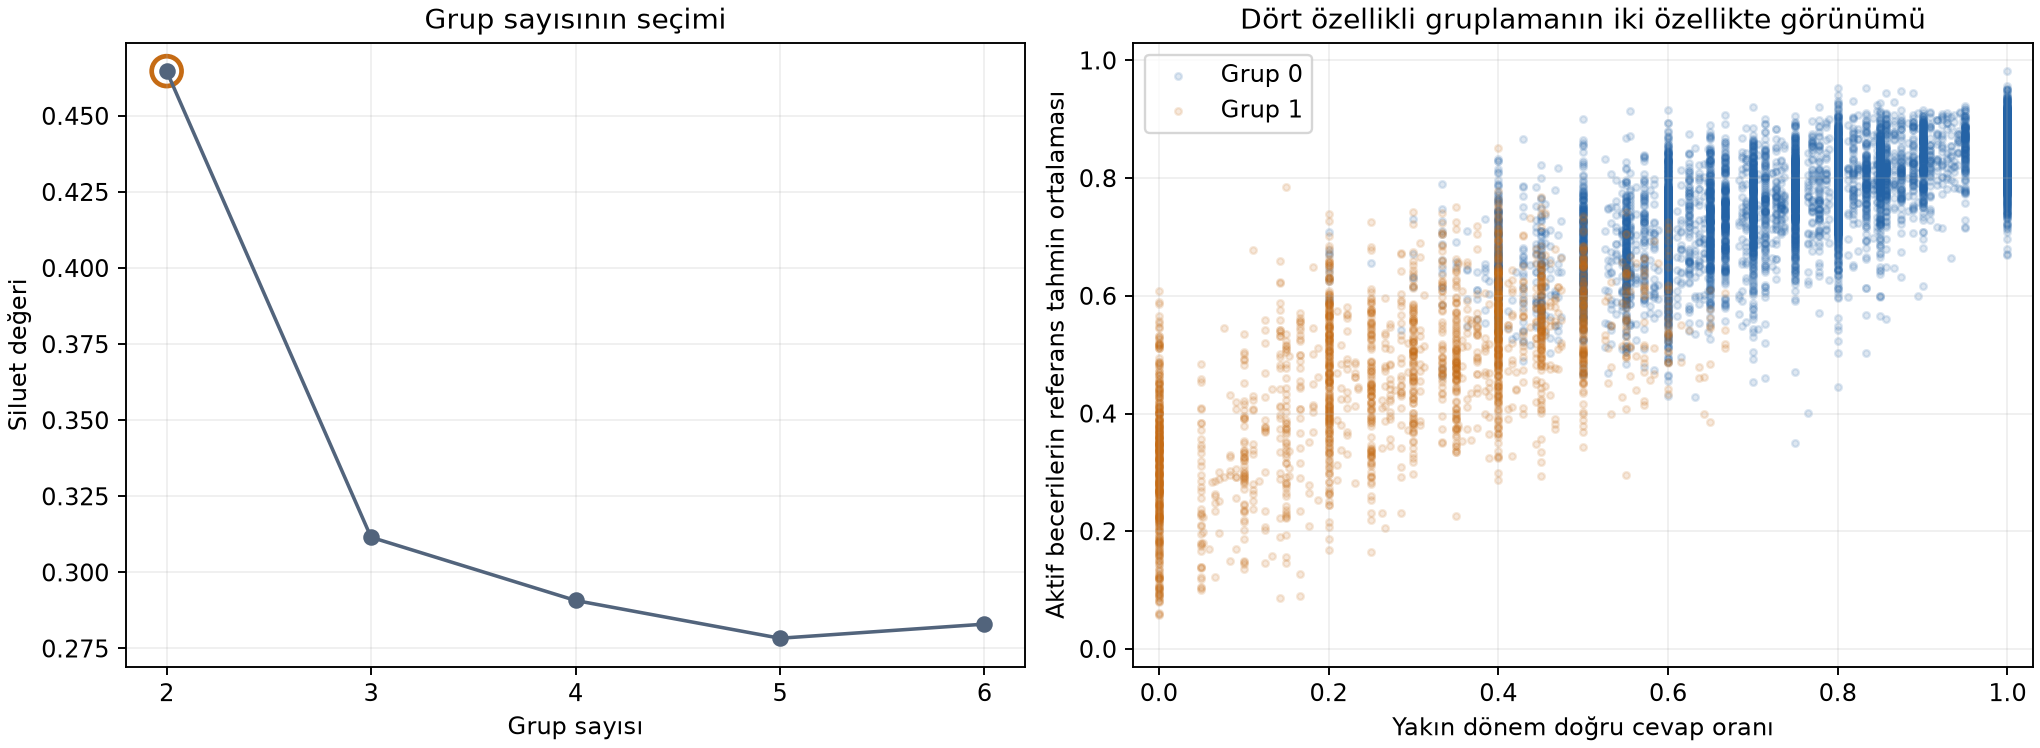

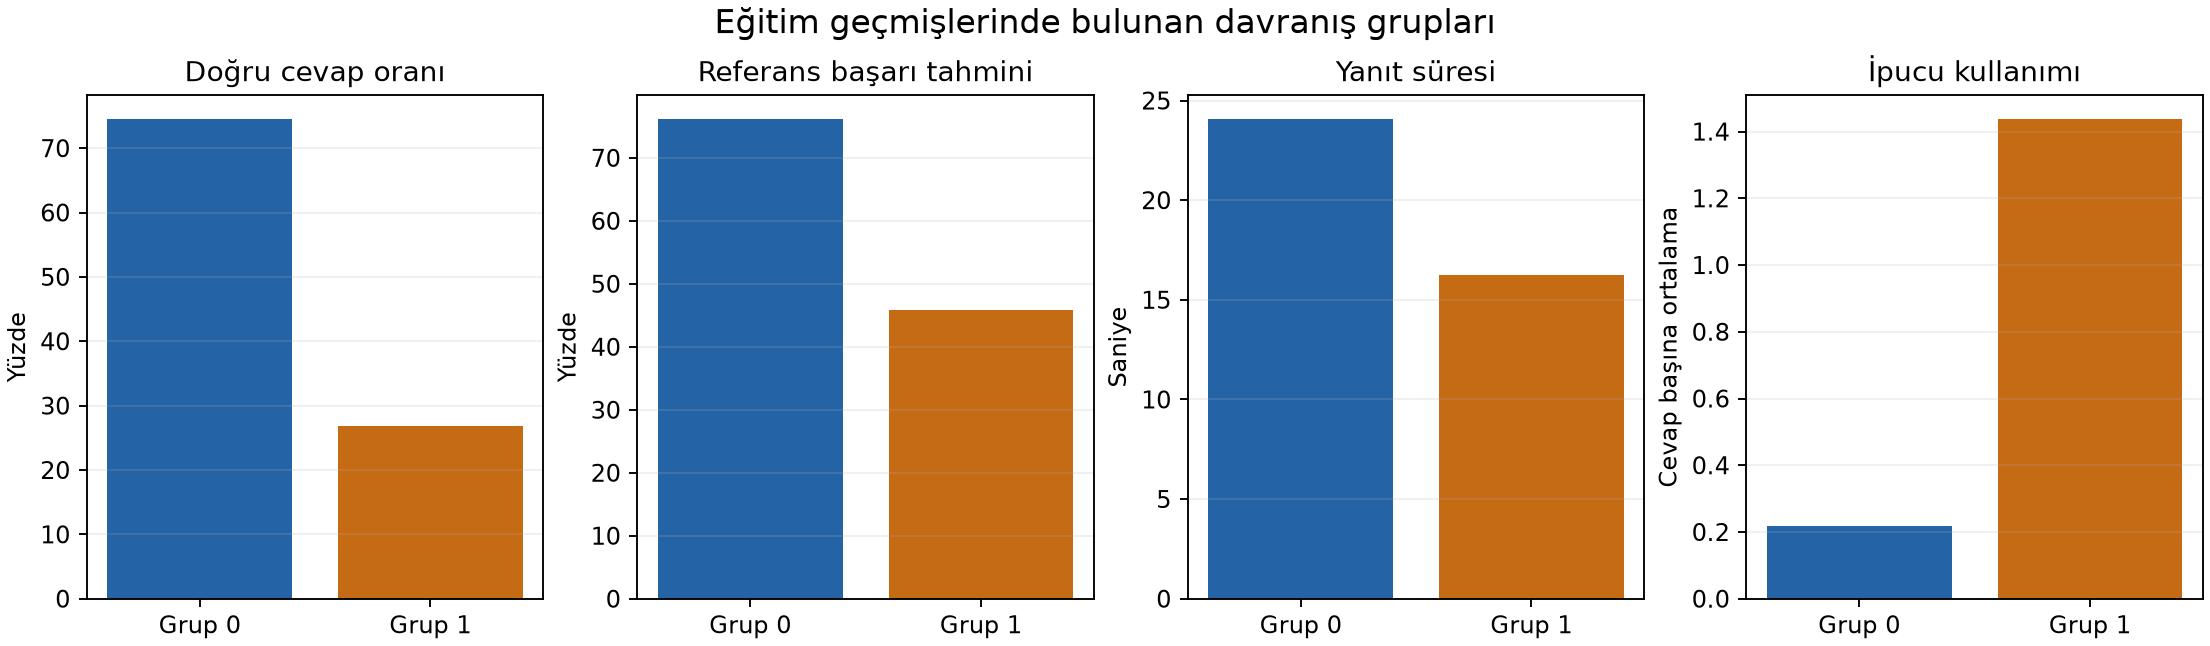

In [4]:
print("Eğitim öğrencisi:", metadata["training_students"])
print("Eğitim geçmişi penceresi:", metadata["training_snapshots"])
display(pd.DataFrame(metadata["candidates"]))
print("Seçilen grup:", metadata["selected_clusters"],
      "Siluet:", round(metadata["selected_silhouette"], 4))
display(pd.DataFrame(metadata["profiles"]))
display(Image(filename=str(ROOT / "outputs/figures/pattern_selection_and_groups.png")))
display(Image(filename=str(ROOT / "outputs/figures/pattern_profiles.png")))

Aynı öğrencinin farklı zamanlardaki pencereleri farklı gruplara girebilir;
profillerdeki öğrenci sayıları toplanmaz. Bunlar kalıcı öğrenme tarzları
değildir. Referans özelliği eğitim geçmişlerinde aynı sabit modelden
üretildiği için burada ayrıca bağımsız gruplama başarısı iddia edilmez.

## Güncel geçmişi öğrenilmiş gruba atama

Aşağıdaki işlem model ve grupları yeniden eğitmeden ilk oturum durumunu
hesaplar. Merkeze uzaklık güven olasılığı olarak yorumlanmaz.

In [5]:
import joblib
patterns = joblib.load(ROOT / "outputs/patterns/behavior_model.joblib")
active = session["initial"]["active_pattern_skills"]
scores = tracer.reference_scores([snapshot], [active], bank)[0]
feature = behavior_vector(store, snapshot, scores, patterns.limits, patterns.window_size)
assignment = patterns.predict(feature)
assert assignment["cluster"] == session["initial"]["behavior"]["cluster"]
display(pd.Series(feature, index=FEATURE_NAMES, name="Güncel özellikler"))
print(assignment)

recent_correct_ratio                  0.200000
active_skill_reference_probability    0.598492
log_median_response_seconds           2.347845
mean_hint_count                       0.000000
Name: Güncel özellikler, dtype: float64

{'cluster': 1, 'description': 'Doğru cevap oranı görece düşük; yanıt süresi görece kısa', 'distance_to_center': 2.212321234273224, 'note': 'En yakın davranış grubudur; güven olasılığı veya kalıcı öğrenme tarzı değildir.'}


**Sonraki defter:** gerçek kayıtları sırayla işleyerek göstergelerin,
grubun ve çalışma önerisinin cevaplardan sonra nasıl değiştiğini gösterir.
Ayrıntılı yöntem `docs/ogrenci_takibi_ve_oruntuler.md` dosyasındadır.